# 06 · Does the starting point explain why ETS beat LightGBM?

In Session 5, LightGBM started every forecast from **the same quarter last year** and lost to ETS, which starts from **the latest quarter**, for 18 of 20 companies. This session changes **one thing**: LightGBM now starts from the latest known quarter. Everything else is fixed: 20 companies, fiscal quarters, per-company origins, the 65-day rule, first-reported revenue, h = 1–4, the same LightGBM settings and seed, retraining at every origin.

- **B3, a new simple rule:** latest known quarter × last year's same step = revenue[t] × revenue[t+h−4] / revenue[t−4]. If Q2 was 25 % above Q1 last year, B3 says this Q2 will be 25 % above this Q1.
- **New target:** the change from the latest quarter, log(revenue[t+h]) − log(revenue[t]). **Forecast** = revenue[t] × exp(predicted change).
- **Features:** last year's same step, plus the Session 5 features (4 year-on-year growths, the latest quarter-on-quarter growth, target fiscal quarter, company type).
- **Placebo:** at every origin, a copy trained with the feature rows shuffled, so features and target no longer belong together.

**Main tests (fixed before evaluating):**
1. One quarter ahead: in how many of the 20 companies does latest-start LightGBM beat ETS?
2. Full year: in how many of the 20 does it beat the company's best simple rule?

Code: `src/latest_start.py`, `src/lgbm_latest.py`, `src/evaluate_latest.py`. The forecasts were made by `lgbm_latest.py run` (about 6 minutes) and saved in `results/session6_latest_forecasts.csv`.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from companies import TYPES
import latest_start as ls
from lgbm_latest import worked_example, leak_check, OUT as LATEST_FORECASTS
from evaluate_types import best_rules, load_forecasts
from evaluate_latest import (ALL, all_methods, per_company, main_tests, by_type, all_horizons,
                             importance, year_2020, sign_test)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
f = all_methods()
t = per_company(f, best_rules(load_forecasts()))

## 1. B3 and the new feature table

In [2]:
table = ls.build_table()
print(f"{len(table):,} rows (the same grid as Session 5)\n")
ls.describe_example(table)
print()
ls.b3_worked_example("Mattel")

5,555 rows (the same grid as Session 5)

Mattel, origin 2013Q1, h = 1: predict the change from 2013Q1 to 2013Q2
  target  = log(rev 2013Q2) - log(rev 2013Q1) = +0.1606  (+17.4 %)
  step_ly = log(rev 2012Q2) - log(rev 2012Q1) = +0.2215  (+24.8 %)   <- last year's same step
  yoy_0   = 2013Q1 vs 2012Q1: +0.0698  (+7.2 %)
  yoy_1   = 2012Q4 vs 2011Q4: +0.0463  (+4.7 %)
  yoy_2   = 2012Q3 vs 2011Q3: +0.0388  (+4.0 %)
  yoy_3   = 2012Q2 vs 2011Q2: -0.0025  (-0.3 %)
  qoq     = 2013Q1 vs 2012Q4: -0.8180  (-55.9 %)
  target_quarter = 2   type = Seasonal
  public_date = 2013-07-25

Mattel, first origin 2013Q1: we pretend it is 2013-06-04; latest known quarter 2013Q1 = 995.6

  h  target  last year step         B3 = latest x step                   B1       B2
  1  2013Q2  2012Q2 / 2012Q1 = 1.2480 995.6 x 1.2480 = 1,242.5        1,158.7  1,204.3
  2  2013Q3  2012Q3 / 2012Q1 = 2.2379 995.6 x 2.2379 = 2,228.1        2,077.8  2,159.5
  3  2013Q4  2012Q4 / 2012Q1 = 2.4298 995.6 x 2.4298 = 2,419.1   

**What this shows:** the new table has the same 5,555 rows as Session 5. Only the target (change from the latest quarter) and one feature (last year's same step) are new. B3 for Mattel starts from Q1 2013 ($995.6 m) and applies last year's steps, so it lands above B1 and B2 at every horizon: Q1 2013 was 7.2 % above Q1 2012, and B3 carries that recent strength forward.

## 2. Worked example: Mattel at its first origin ($m)

In [3]:
worked_example("Mattel")

Mattel, first origin 2013Q1: we pretend it is 2013-06-04; start = latest known quarter 2013Q1 = 995.6

  h  target  train rows  pred. change  latest-start   placebo        B3  Session 5       ETS
  1  2013Q2         340        +28.0%       1,273.9     938.2   1,242.5    1,247.4   1,212.7
  2  2013Q3         321       +120.2%       2,191.9   1,082.8   2,228.1    2,165.0   2,058.6
  3  2013Q4         303       +113.5%       2,125.5   1,193.6   2,419.1    2,340.9   2,186.9
  4  2014Q1         284         +2.0%       1,015.4   1,161.9   1,067.6    1,015.4     963.7

  latest-start = 2013Q1 x exp(predicted change); all in $m.


**What this shows:** the latest-start model learned Mattel's seasonal jumps (it predicts Q3 at about 2.2 times Q1, close to B3). The shuffled placebo can't: without knowing which quarter it is forecasting, it gives a flat $938–1,194 m. Four quarters ahead, latest-start equals Session 5 exactly ($1,015.4 m), because at h = 4 "the latest quarter" is "the same quarter last year". So the two models can only differ at h = 1–3.

## 3. Leak check on every forecast (all counts must be 0)

In [4]:
g = pd.read_csv(LATEST_FORECASTS, parse_dates=["cutoff", "train_max_public", "row_public"])
for col in ["origin", "target", "start_q"]:
    g[col] = pd.PeriodIndex(g[col], freq="Q")
print("forecasts starting from an older quarter (origin quarter not yet public):", int((g["start_q"] < g["origin"]).sum()),
      "| B3 used because no model that far ahead:", int(g["fallback_b3"].sum()))
leak_check(g)

forecasts starting from an older quarter (origin quarter not yet public): 5 | B3 used because no model that far ahead: 1


forecasts                                              4036
training data public after the cutoff                     0
forecast row uses a quarter public after the cutoff       0
start quarter after the origin                            0
target not after the origin                               0
dtype: int64

## 4. Main tests
A **sign test** treats each company as a coin toss: if two methods were equally good, each would win about half. Two-sided. **Caveat:** the companies share shocks (2020 above all), so they aren't fully independent and the p-values are somewhat too optimistic.

In [5]:
main_tests(t).round(4)

,companies,wins,sign test p (two-sided)
test,,,
h=1: latest-start LightGBM beats ETS,20,4,0.01
full year: latest-start LightGBM beats the best simple rule,20,11,0.82


**What this shows:** starting from the latest quarter did **not** make LightGBM beat ETS. It wins for 4 of 20 companies (Salesforce, Netflix, Adobe, Church & Dwight), up from 2 in Session 5. A split that lopsided would happen by chance only about 1 % of the time, so LightGBM is still reliably worse than ETS one quarter ahead. For the full year it beats the best simple rule for 11 of 20 again, a coin flip (p = 0.82).

## 5. Per company
MAPE in % (h1 = one quarter ahead, FY = full year). DM p-values are not corrected and are listed for information only.

In [6]:
t[["type", "h1 ETS", "h1 LGBM", "h1 LATEST", "h1 B3", "beats ETS h1", "p vs ETS h1",
   "best rule", "FY rule", "FY LATEST", "beats rule FY", "p vs rule FY"]].round(2)

,type,h1 ETS,h1 LGBM,h1 LATEST,h1 B3,beats ETS h1,p vs ETS h1,best rule,FY rule,FY LATEST,beats rule FY,p vs rule FY
Mattel,Seasonal,7.49,8.04,8.60,7.68,False,0.27,B1,6.36,6.81,False,0.69
Hasbro,Seasonal,10.14,10.39,10.57,10.95,False,0.72,B2,11.08,10.04,True,0.69
Williams-Sonoma,Seasonal,3.66,3.78,4.56,4.13,False,0.16,B2,6.69,4.41,True,0.10
Best Buy,Seasonal,4.07,4.47,4.28,5.14,False,0.75,B2,7.63,5.92,True,0.20
Macy's,Seasonal,5.25,6.32,6.30,6.09,False,0.13,B2,9.67,6.95,True,0.26
Alphabet,Growth tech,3.41,3.73,3.42,3.80,False,0.99,B2,7.19,5.18,True,0.22
Microsoft,Growth tech,3.83,4.54,4.35,4.23,False,0.32,B2,6.44,5.29,True,0.11
Salesforce,Growth tech,2.39,1.91,1.81,1.71,True,0.04,B2,3.04,2.60,True,0.54
Netflix,Growth tech,2.14,2.20,2.04,2.15,True,0.67,B2,4.31,3.92,True,0.64
Adobe,Growth tech,2.63,2.44,2.47,2.31,True,0.69,B2,3.87,3.95,False,0.90


**What this shows:** latest-start is close to ETS for the growth companies (Alphabet 3.42 vs 3.41 %) and falls well behind for Deere (8.3 vs 5.5 %), PACCAR (10.0 vs 8.0 %) and Clorox (7.1 vs 5.0 %). For the full year it beats the best simple rule mainly where that rule was weak (the seasonal retailers, the growth companies, Deere).

## 6. How much of Session 5's gap to ETS closed?
"Gap" = LightGBM's h = 1 MAPE minus ETS's. Share closed = (old gap − new gap) / old gap: 1 means the whole gap closed, below 0 means it got worse. It's not defined where Session 5 already beat ETS (Salesforce, Adobe).

In [7]:
t[["type", "gap to ETS, S5", "gap to ETS, S6", "share of gap closed", "beats LGBM h1"]].round(2)

,type,"gap to ETS, S5","gap to ETS, S6",share of gap closed,beats LGBM h1
Mattel,Seasonal,0.55,1.11,-1.02,False
Hasbro,Seasonal,0.25,0.43,-0.74,False
Williams-Sonoma,Seasonal,0.12,0.90,-6.73,False
Best Buy,Seasonal,0.40,0.21,0.48,True
Macy's,Seasonal,1.08,1.05,0.03,True
Alphabet,Growth tech,0.32,0.00,0.99,True
Microsoft,Growth tech,0.71,0.52,0.27,True
Salesforce,Growth tech,-0.49,-0.58,NaN,True
Netflix,Growth tech,0.06,-0.10,2.66,True
Adobe,Growth tech,-0.19,-0.16,NaN,False


In [8]:
w = int(t["beats LGBM h1"].sum())
print(f"Latest-start beats Session 5 LightGBM for {w} of 20 companies (sign test p = {sign_test(w, 20):.3f})")
by_type(t).round(2)

Latest-start beats Session 5 LightGBM for 14 of 20 companies (sign test p = 0.115)


,h1 ETS,h1 LGBM,h1 LATEST,h1 B3,h1 PLACEBO,FY LATEST,FY rule,share of gap closed,beats ETS h1,beats rule FY,beats B3 h1,B3 beats old best rule
type,,,,,,,,,,,,
Seasonal,6.12,6.60,6.86,6.80,30.27,6.83,8.29,-0.55,0/5,4/5,2/5,4/5
Growth tech,2.88,2.97,2.82,2.84,6.83,4.19,4.97,1.76,3/5,4/5,2/5,5/5
Cyclical industrial,5.75,6.61,6.85,7.39,9.74,9.73,9.88,-0.28,0/5,1/5,3/5,3/5
FMCG,2.95,4.01,3.67,3.79,7.24,3.90,3.61,0.32,1/5,2/5,4/5,3/5


**What this shows:** the gap to ETS did not close on average. Latest-start beats Session 5 for 14 of 20 companies (p = 0.12), but the improvements (3.6 points in total) and the setbacks (3.6 points) cancel out, so the mean one-quarter-ahead MAPE is 5.04 % for both. By type, the gap **closed completely for growth tech** (latest-start now averages 2.82 % vs ETS 2.88 %) and by about a third for FMCG. It **widened** for seasonal companies and cyclicals, mostly Williams-Sonoma, Mattel, Deere and PACCAR. Caterpillar is the exception among cyclicals: 83 % of its gap closed.

## 7. The simple versions: latest-start vs B3, and B3 vs the old best simple rules

In [9]:
for col, label in [("beats B3 h1", "Latest-start LightGBM beats B3"),
                   ("B3 beats old best rule", "B3 beats the company's old best simple rule (B0/B1/B2)")]:
    w = int(t[col].sum())
    print(f"{label}: {w} of 20 (sign test p = {sign_test(w, 20):.3f})")
t[["type", "best rule", "h1 best rule", "h1 B3", "B3 beats old best rule", "h1 LATEST", "beats B3 h1"]].round(2)

Latest-start LightGBM beats B3: 11 of 20 (sign test p = 0.824)
B3 beats the company's old best simple rule (B0/B1/B2): 15 of 20 (sign test p = 0.041)


,type,best rule,h1 best rule,h1 B3,B3 beats old best rule,h1 LATEST,beats B3 h1
Mattel,Seasonal,B1,8.89,7.68,True,8.60,False
Hasbro,Seasonal,B2,10.25,10.95,False,10.57,True
Williams-Sonoma,Seasonal,B2,5.65,4.13,True,4.56,False
Best Buy,Seasonal,B2,6.03,5.14,True,4.28,True
Macy's,Seasonal,B2,8.86,6.09,True,6.30,False
Alphabet,Growth tech,B2,5.66,3.80,True,3.42,True
Microsoft,Growth tech,B2,5.68,4.23,True,4.35,False
Salesforce,Growth tech,B2,2.65,1.71,True,1.81,False
Netflix,Growth tech,B2,3.59,2.15,True,2.04,True
Adobe,Growth tech,B2,3.35,2.31,True,2.47,False


**What this shows:** two findings. First, latest-start LightGBM beats its simple version B3 for only **11 of 20** companies (p = 0.82), so the machine learning adds almost nothing on top of B3. Second, **B3 itself beats each company's old best simple rule for 15 of 20** (p = 0.04): all five growth companies, four of five seasonal ones (not Hasbro), and three of five in both cyclicals and FMCG. It loses where "last quarter" was best (Cummins, PACCAR, Colgate) and for Hasbro and Clorox, whose quarters jump around.

## 8. Placebo: shuffled features
The same model trained with the feature rows shuffled. It should be clearly worse.

In [10]:
r = t["h1 PLACEBO"] / t["h1 LATEST"]
print(f"Placebo worse for {int((r > 1).sum())} of 20 companies; median {r.median():.2f} times the real MAPE")
t[["type", "h1 LATEST", "h1 PLACEBO"]].assign(ratio=r).round(2)

Placebo worse for 19 of 20 companies; median 2.31 times the real MAPE


,type,h1 LATEST,h1 PLACEBO,ratio
Mattel,Seasonal,8.60,45.26,5.26
Hasbro,Seasonal,10.57,32.86,3.11
Williams-Sonoma,Seasonal,4.56,17.86,3.91
Best Buy,Seasonal,4.28,26.16,6.12
Macy's,Seasonal,6.30,29.21,4.64
Alphabet,Growth tech,3.42,9.10,2.66
Microsoft,Growth tech,4.35,9.27,2.13
Salesforce,Growth tech,1.81,5.12,2.83
Netflix,Growth tech,2.04,5.49,2.69
Adobe,Growth tech,2.47,5.18,2.10


**What this shows:** with shuffled features the model is worse for 19 of 20 companies, typically 2.3 times the error, and about 5 times for seasonal companies (it can't tell which quarter it's forecasting). So the real model does use its features. The one exception is PACCAR, where the placebo (8.6 %) beats the real model (10.0 %). A shuffled model forecasts "latest quarter × average change", close to "last quarter", which is PACCAR's best rule. That suggests the real model reads too much into PACCAR's step from last year.

## 9. All horizons (mean MAPE over all forecasts, %)

In [11]:
all_horizons(f).round(2)

baseline,ETS,LGBM,LATEST,B3,B2,PLACEBO
h,,,,,,
1,4.41,5.04,5.04,5.18,6.95,13.25
2,6.25,6.91,7.07,7.33,8.45,17.46
3,7.67,8.06,8.03,8.95,9.55,16.27
4,8.87,9.14,9.14,10.65,10.50,10.97


**What this shows:** across all forecasts, latest-start ties Session 5 one quarter ahead (5.04 %), is slightly worse two quarters ahead (7.07 vs 6.91 %), slightly better three ahead (8.03 vs 8.06 %), and identical four ahead, as it must be. ETS is best at every horizon. B3 beats B2 at h = 1–3, but not four quarters ahead (10.65 vs 10.50 %).

## 10. What the models lean on (feature importance, % of split gain, final models)

In [12]:
importance().round(1)

,h=1,h=2,h=3,h=4
step_ly,88.30,78.50,10.90,24.30
yoy_0,2.90,3.20,2.20,0.00
qoq,2.40,9.10,74.20,8.60
target_quarter,1.90,1.00,1.50,0.40
yoy_1,1.50,2.90,3.50,8.80
yoy_3,1.50,1.30,2.20,18.00
type,0.80,2.10,4.20,31.60
yoy_2,0.60,1.90,1.20,8.30


**What this shows:** one and two quarters ahead the model leans almost entirely on **last year's same step** (88 % and 79 % of the gain): "this year's Q1→Q2 step will look like last year's". Three quarters ahead, the **latest quarter-on-quarter change** takes over (74 %). The target is then the same fiscal quarter as the one *before* the latest, so the forecast is roughly "undo the latest quarter's jump, plus a year of growth". Four quarters ahead it's the same model as Session 5, where company type matters most.

## 11. The year 2020 (h = 1 MAPE, targets ending in calendar 2020 vs other years)

In [13]:
year_2020(f).round(1)

baseline              ETS             LATEST              LGBM            
when                 2020 other years   2020 other years  2020 other years
type                                                                      
Seasonal            13.60        5.60  16.00        6.30 16.90        5.90
Growth tech          3.80        2.80   3.80        2.70  4.30        2.90
Cyclical industrial 17.30        4.80  16.40        6.00 14.10        6.00
FMCG                 4.90        2.80   4.60        3.60  4.30        4.00

**What this shows:** in 2020, latest-start did better than Session 5 for seasonal (16.0 vs 16.9 %) and growth companies (3.8 vs 4.3 %), and worse for cyclicals (16.4 vs 14.1 %) and FMCG (4.6 vs 4.4 %). Compared with ETS it was slightly better for cyclicals and FMCG and worse for seasonal retailers. Starting from the latest quarter helps when that quarter is informative, and hurts when it's a one-off shock.

## 12. Summary chart: the gap to ETS, before and after
For each company, LightGBM's h = 1 MAPE minus ETS's, in Session 5 (from last year's quarter) and Session 6 (from the latest quarter). Left of the line = LightGBM beats ETS.

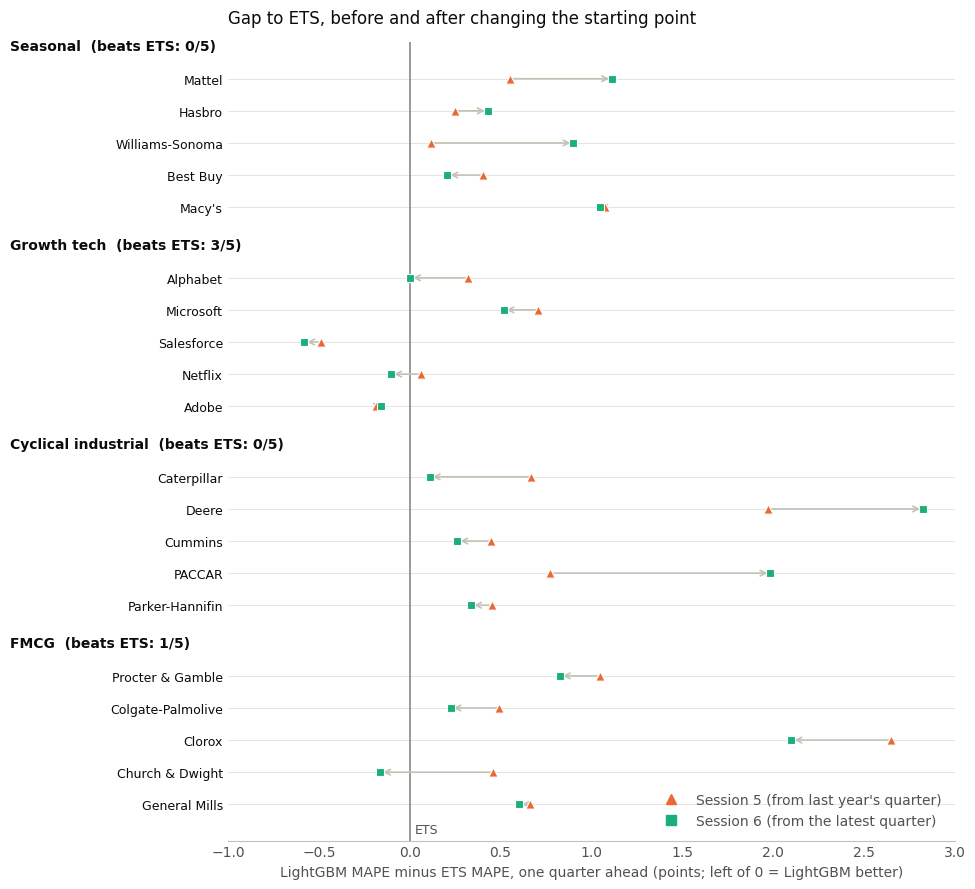

In [14]:
S5C, S6C = "#eb6834", "#1baf7a"                 # default palette slots 2-3
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
rows, y = [], 0
for ty in TYPES:
    for c in [c for c in ALL if t.loc[c, "type"] == ty]:
        rows.append((y, c)); y += 1
    y += 1.2
fig, ax = plt.subplots(figsize=(10, 9))
ax.axvline(0, color="#898781", lw=1.2, zorder=1)
ax.text(0.03, rows[-1][0] + 0.9, "ETS", ha="left", color=MUTED, fontsize=9)
for yy, c in rows:
    a, b = t.loc[c, "gap to ETS, S5"], t.loc[c, "gap to ETS, S6"]
    ax.hlines(yy, -1, 3, color=GRID, lw=0.6, zorder=0)
    ax.annotate("", xy=(b, yy), xytext=(a, yy), arrowprops=dict(arrowstyle="->", color="#c3c2b7", lw=1.2), zorder=2)
    ax.scatter(a, yy, color=S5C, marker="^", s=45, edgecolor="white", lw=0.8, zorder=3)
    ax.scatter(b, yy, color=S6C, marker="s", s=40, edgecolor="white", lw=0.8, zorder=3)
ax.set_yticks([r[0] for r in rows], [c for _, c in rows], fontsize=9, color=INK)
ax.invert_yaxis()
for ty in TYPES:
    ys = [yy for yy, c in rows if t.loc[c, "type"] == ty]
    ax.text(-0.3, min(ys) - 0.9, f"{ty}  (beats ETS: {int(t[t['type'] == ty]['beats ETS h1'].sum())}/5)",
            transform=ax.get_yaxis_transform(), color=INK, fontsize=10, fontweight="bold", ha="left")
ax.set_xlim(-1, 3)
ax.set_xlabel("LightGBM MAPE minus ETS MAPE, one quarter ahead (points; left of 0 = LightGBM better)", color=MUTED)
ax.tick_params(axis="x", colors=MUTED, length=0); ax.tick_params(axis="y", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
handles = [plt.Line2D([], [], color=S5C, marker="^", ls="", markersize=7, label="Session 5 (from last year's quarter)"),
           plt.Line2D([], [], color=S6C, marker="s", ls="", markersize=7, label="Session 6 (from the latest quarter)")]
ax.legend(handles=handles, frameon=False, loc="lower right", ncol=1, labelcolor=MUTED)
ax.set_title("Gap to ETS, before and after changing the starting point", loc="left", color=INK, fontsize=12, pad=14)
fig.tight_layout()
plt.show()

**What this shows:** each arrow goes from Session 5's gap to ETS (triangle) to Session 6's (square); left of the grey line means LightGBM beats ETS. For growth companies, Caterpillar, Church & Dwight and Colgate the arrows point left, towards or past ETS. For Mattel, Williams-Sonoma, Deere and PACCAR they point right: starting from the latest quarter made things worse.

## Summary

| Test (fixed in advance) | Wins | Sign test p |
|---|---|---|
| h = 1: latest-start LightGBM beats ETS | 4 of 20 | 0.012 (still worse) |
| Full year: beats the best simple rule | 11 of 20 | 0.82 |

**Plainly:** the starting point is **not** the whole reason ETS beat LightGBM. Changing it closed the gap for growth companies and partly for FMCG, but widened it for seasonal companies and cyclicals; on average nothing changed. LightGBM still loses to ETS for 16 of 20 companies, and it barely beats its own simple version B3 (11 of 20).

**The useful finding is B3.** "Latest quarter × last year's same step" beats each company's old best simple rule for 15 of 20 companies (p = 0.04). For an FP&A team that wants one simple rule, it's a better default than "same quarter last year (× growth)". It still trails ETS (5.2 vs 4.4 % one quarter ahead).

The bars stay: ETS one quarter ahead, and the best simple rule for the full year, with B3 now a strong simple benchmark.